# Розпізнавання рукописних цифр методами машинного навчання
**Навчальний експеримент: порівняння моделей, підбір параметрів та аналіз помилок.**

Автор: ____________________   Група: ____________________

## 1. Мета та дослідницькі питання
Побудувати класифікатор, який за зображенням 8 × 8 визначає цифру від 0 до 9.
Перевіримо, чи нелінійна SVM перевершує логістичну регресію за macro-F1
на кросвалідації; порівняємо також випадковий ліс і простий базовий прогноз.
Окремо дослідимо вплив обсягу навчання та штучного шуму.
Гіпотези перевіряються результатами, а не вважаються наперед доведеними.

Це багатокласова класифікація з учителем: X ∈ R^(n×64), y ∈ {0,…,9}.
Навчаємо готові реалізації scikit-learn; власних реалізацій алгоритмів немає.

## 2. Протокол експерименту
Фіксуємо seed=42 і stratified train/test=80/20. Test відкриваємо після
вибору моделі та параметрів за 5-fold CV на train. Основна метрика — macro-F1.
StandardScaler навчається всередині Pipeline окремо в кожному fold.
Learning curve використовує лише train. Після test модель не змінюємо.
Наперед фіксуємо noise sigma={0,1,2,4}: це додатковий stress test, не оптимізація.
Жодна точність не є вимогою до результату чи підставою міняти seed.

In [1]:
from pathlib import Path
import json
import platform
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import scipy
from scipy.stats import binomtest
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display, Markdown

SEED = 42
OUT = Path('results')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.family': 'DejaVu Sans', 'axes.spines.top': False, 'axes.spines.right': False})
versions = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__, 'scikit-learn': sklearn.__version__, 'scipy': scipy.__version__}
display(pd.Series(versions, name='Версія').to_frame())

def save_figure(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close()

,Версія
python,3.12.14
numpy,2.5.4
pandas,3.1.1
scikit-learn,1.9.1
scipy,1.18.1


## 3. Дані та походження
Digits — вбудований у scikit-learn навчальний набір із 1797 зображень
рукописних цифр 8 × 8. Кожен піксель має інтенсивність від 0 до 16.
Вектор із 64 пікселів — ознаки, цифра — цільова мітка.
Дані є копією тестової частини UCI Optical Recognition of Handwritten Digits;
тут ми створюємо власне навчальне й тестове розбиття цієї копії.
Не слід плутати Digits із MNIST (інший набір, інша роздільність).
Джерела: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html),
[UCI](https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits).

Всього: 1797, ознак: 64; train: 1437, test: 360
Пропущених значень: 0; діапазон пікселів: 0.0…16.0


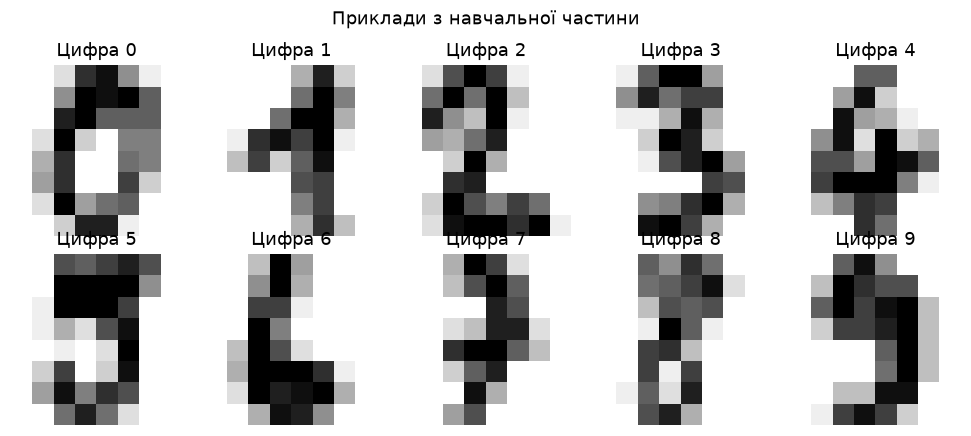

In [2]:
digits = load_digits()
X, y = digits.data, digits.target
indices = np.arange(len(y))
train_idx, test_idx = train_test_split(indices, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_test, y_train, y_test = X[train_idx], X[test_idx], y[train_idx], y[test_idx]
assert not set(train_idx) & set(test_idx)
assert np.isfinite(X).all()
assert set(y_train) == set(y_test) == set(range(10))
print(f'Всього: {X.shape[0]}, ознак: {X.shape[1]}; train: {len(train_idx)}, test: {len(test_idx)}')
print(f'Пропущених значень: {np.isnan(X).sum()}; діапазон пікселів: {X.min()}…{X.max()}')
# Повторні зображення у двох частинах зробили б оцінку оптимістичною.
assert not ({row.tobytes() for row in X_train} & {row.tobytes() for row in X_test})
fig, axes = plt.subplots(2, 5, figsize=(9, 4))
for label, ax in enumerate(axes.flat):
    sample = X_train[y_train == label][0].reshape(8, 8)
    ax.imshow(sample, cmap='gray_r', vmin=0, vmax=16)
    ax.set_title(f'Цифра {label}')
    ax.axis('off')
fig.suptitle('Приклади з навчальної частини')
save_figure('samples')

,train,test
Цифра,,
0,142,36
1,146,36
2,142,35
3,146,37
4,145,36
5,145,37
6,145,36
7,143,36
8,139,35


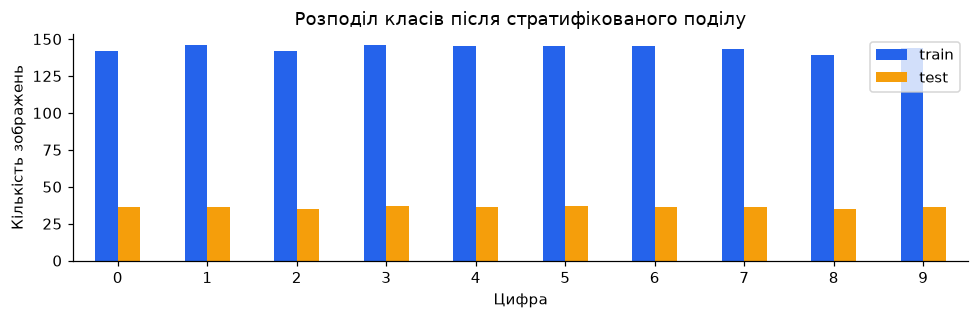

In [3]:
balance = pd.DataFrame({'train': np.bincount(y_train, minlength=10), 'test': np.bincount(y_test, minlength=10)})
balance.index.name = 'Цифра'
display(balance)
balance.plot.bar(figsize=(9, 3), rot=0, color=['#2563eb', '#f59e0b'])
plt.ylabel('Кількість зображень')
plt.title('Розподіл класів після стратифікованого поділу')
save_figure('class_balance')

## 4. Моделі та метрики
**DummyClassifier** завжди повертає найчастіший клас — мінімальний орієнтир.
**LogisticRegression** навчає лінійні межі між класами.
**SVC із RBF-ядром** може описувати нелінійні межі; C керує регуляризацією,
gamma — масштабом впливу окремих спостережень.
**RandomForest** об'єднує дерева; max_depth обмежує їхню складність.
Масштабування потрібне моделям із чутливістю до масштабу ознак, але не лісу.

Accuracy = кількість правильних відповідей / кількість прикладів.
Для кожного класу precision = TP/(TP+FP), recall = TP/(TP+FN),
F1 = 2·precision·recall/(precision+recall).
Macro-F1 — середнє F1 десяти класів із однаковою вагою кожного.
CV std показує розкид між folds, а не довірчий інтервал.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
experiments = {
    'Dummy': (DummyClassifier(strategy='most_frequent'), {}),
    'LogisticRegression': (Pipeline([('scale', StandardScaler()), ('model', LogisticRegression(max_iter=3000, random_state=SEED))]), {'model__C': [0.1, 1, 10]}),
    'SVC': (Pipeline([('scale', StandardScaler()), ('model', SVC(kernel='rbf'))]), {'model__C': [1, 5, 10], 'model__gamma': ['scale', 0.001, 0.01]}),
    'RandomForest': (RandomForestClassifier(n_estimators=150, random_state=SEED, n_jobs=1), {'max_depth': [None, 12], 'max_features': ['sqrt', 0.5]}),
}
searches, rows = {}, []
for name, (estimator, grid) in experiments.items():
    start = time.perf_counter()
    search = GridSearchCV(estimator, grid, scoring={'macro_f1': 'f1_macro', 'accuracy': 'accuracy'}, refit='macro_f1', cv=cv, n_jobs=1, return_train_score=True, error_score='raise')
    search.fit(X_train, y_train)
    searches[name] = search
    i = search.best_index_
    rows.append({'model': name, 'cv_macro_f1': search.best_score_, 'cv_std': search.cv_results_['std_test_macro_f1'][i], 'cv_accuracy': search.cv_results_['mean_test_accuracy'][i], 'train_macro_f1': search.cv_results_['mean_train_macro_f1'][i], 'seconds': time.perf_counter() - start, 'best_params': str(search.best_params_)})
    pd.DataFrame(search.cv_results_).to_csv(OUT / f'grid_{name}.csv', index=False)
    print(f'{name}: CV macro-F1={search.best_score_:.4f}')
comparison = pd.DataFrame(rows).set_index('model').sort_values('cv_macro_f1', ascending=False)
selected_name = comparison.index[0]  # Тільки train CV, без test!
best_model = searches[selected_name].best_estimator_
comparison.to_csv(OUT / 'cv_comparison.csv')
display(comparison.round(4))
print('Обрана за CV модель:', selected_name)

Dummy: CV macro-F1=0.0183


LogisticRegression: CV macro-F1=0.9679


SVC: CV macro-F1=0.9812


RandomForest: CV macro-F1=0.9763


,cv_macro_f1,cv_std,cv_accuracy,train_macro_f1,seconds,best_params
model,,,,,,
SVC,0.9812,0.0059,0.9812,0.9976,10.2232,"{'model__C': 1, 'model__gamma': 'scale'}"
RandomForest,0.9763,0.0081,0.9763,1.0000,32.0530,"{'max_depth': 12, 'max_features': 'sqrt'}"
LogisticRegression,0.9679,0.0073,0.9680,0.9997,0.8059,{'model__C': 1}
Dummy,0.0183,0.0000,0.1009,0.0185,0.0778,{}


Обрана за CV модель: SVC


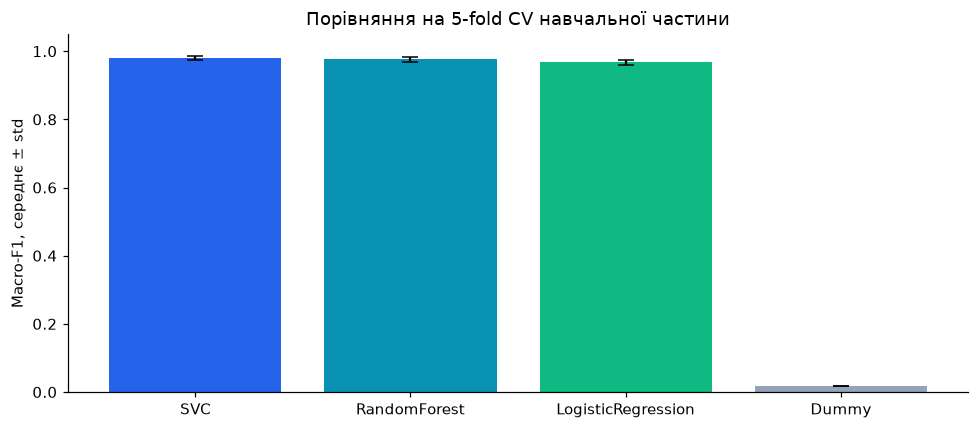

**Перевірка гіпотези:** SVC − LogisticRegression = **+0.0133** macro-F1. Це описове порівняння на одному розбитті; статистичної значущості різниці не стверджуємо. Найкраща оцінка CV після пошуку може бути оптимістичною, тому потрібен незалежний test.

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(comparison.index, comparison.cv_macro_f1, yerr=comparison.cv_std, capsize=5, color=['#2563eb', '#0891b2', '#10b981', '#94a3b8'])
ax.set_ylim(0, 1.05)
ax.set_ylabel('Macro-F1, середнє ± std')
ax.set_title('Порівняння на 5-fold CV навчальної частини')
save_figure('cv_comparison')
svc_score = comparison.loc['SVC', 'cv_macro_f1']
lr_score = comparison.loc['LogisticRegression', 'cv_macro_f1']
display(Markdown(f'**Перевірка гіпотези:** SVC − LogisticRegression = **{svc_score-lr_score:+.4f}** macro-F1. Це описове порівняння на одному розбитті; статистичної значущості різниці не стверджуємо. Найкраща оцінка CV після пошуку може бути оптимістичною, тому потрібен незалежний test.'))

## 5. Крива навчання (тільки train)
Після фіксації моделі перевіряємо її на різних обсягах навчальних даних
із 3-fold стратифікованою CV. Великий розрив train/validation може вказувати
на перенавчання; зростання validation зі збільшенням даних — на користь нових даних.
Цей графік діагностичний: після нього параметри не змінюємо.

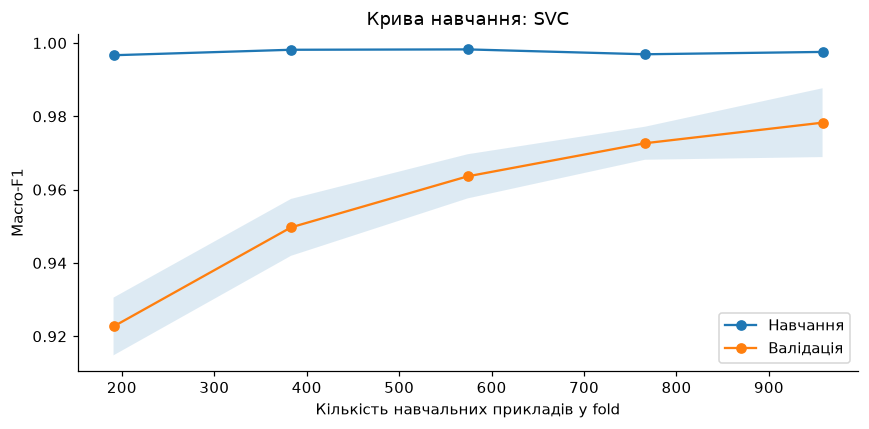

In [6]:
sizes, train_scores, validation_scores = learning_curve(
    best_model, X_train, y_train,
    train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0],
    cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
    scoring='f1_macro', shuffle=True, random_state=SEED, n_jobs=1)
curve = pd.DataFrame({'n': sizes, 'train_f1': train_scores.mean(axis=1), 'validation_f1': validation_scores.mean(axis=1), 'validation_std': validation_scores.std(axis=1)})
curve.to_csv(OUT / 'learning_curve.csv', index=False)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sizes, train_scores.mean(axis=1), 'o-', label='Навчання')
ax.plot(sizes, validation_scores.mean(axis=1), 'o-', label='Валідація')
ax.fill_between(sizes, validation_scores.mean(axis=1)-validation_scores.std(axis=1), validation_scores.mean(axis=1)+validation_scores.std(axis=1), alpha=0.15)
ax.set(xlabel='Кількість навчальних прикладів у fold', ylabel='Macro-F1', title=f'Крива навчання: {selected_name}')
ax.legend()
save_figure('learning_curve')

## 6. Фінальне оцінювання
Тепер застосовуємо обрану модель до відкладених 360 зображень.
Поруч наводимо baseline. Інші моделі не обираємо повторно за test.
95% Wilson-інтервал accuracy показує невизначеність оцінки за припущення
незалежних спостережень; він не враховує зміну авторів почерку чи джерела даних.

In [7]:
pred = best_model.predict(X_test)
baseline_pred = searches['Dummy'].best_estimator_.predict(X_test)
accuracy = accuracy_score(y_test, pred)
macro_f1 = f1_score(y_test, pred, average='macro')
baseline_accuracy = accuracy_score(y_test, baseline_pred)
correct = int(np.sum(pred == y_test))
ci = binomtest(correct, len(y_test)).proportion_ci(confidence_level=0.95, method='wilson')
display(pd.DataFrame([
    {'Модель': 'Dummy', 'Accuracy': baseline_accuracy, 'Macro-F1': f1_score(y_test, baseline_pred, average='macro', zero_division=0)},
    {'Модель': selected_name, 'Accuracy': accuracy, 'Macro-F1': macro_f1},
]).set_index('Модель').round(4))
print(f'Правильних відповідей: {correct}/{len(y_test)}; 95% Wilson CI: [{ci.low:.4f}, {ci.high:.4f}]')
report = pd.DataFrame(classification_report(y_test, pred, output_dict=True, zero_division=0)).T
report.to_csv(OUT / 'classification_report.csv')
display(report.round(4))
pd.DataFrame({'dataset_index': test_idx, 'true': y_test, 'predicted': pred}).to_csv(OUT / 'test_predictions.csv', index=False)

,Accuracy,Macro-F1
Модель,,
Dummy,0.100,0.0182
SVC,0.975,0.9748


Правильних відповідей: 351/360; 95% Wilson CI: [0.9532, 0.9868]


,precision,recall,f1-score,support
0,1.0000,1.0000,1.0000,36.000
1,0.9459,0.9722,0.9589,36.000
2,1.0000,1.0000,1.0000,35.000
3,1.0000,1.0000,1.0000,37.000
4,0.9459,0.9722,0.9589,36.000
5,0.9737,1.0000,0.9867,37.000
6,0.9730,1.0000,0.9863,36.000
7,0.9211,0.9722,0.9459,36.000
8,1.0000,0.9143,0.9552,35.000
9,1.0000,0.9167,0.9565,36.000


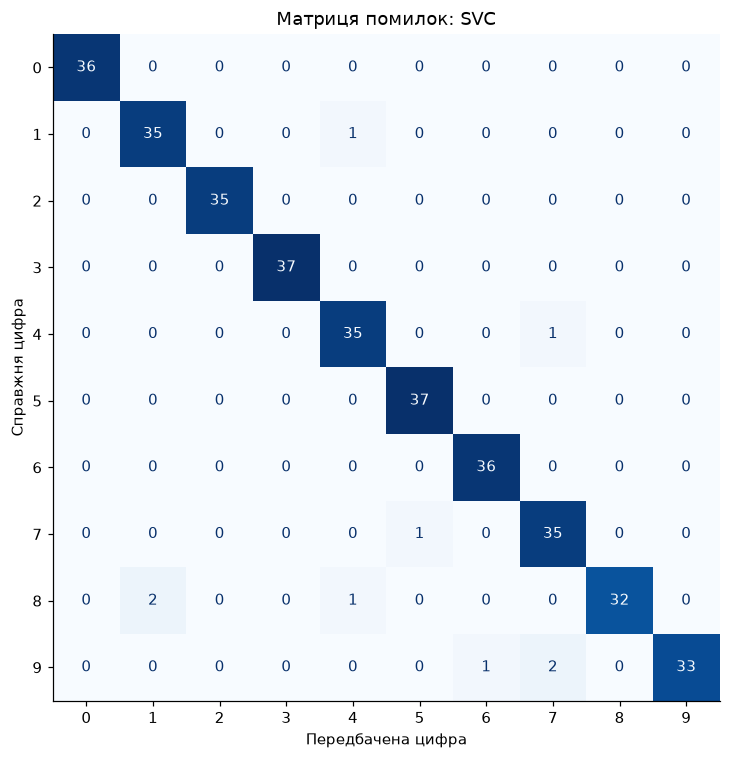

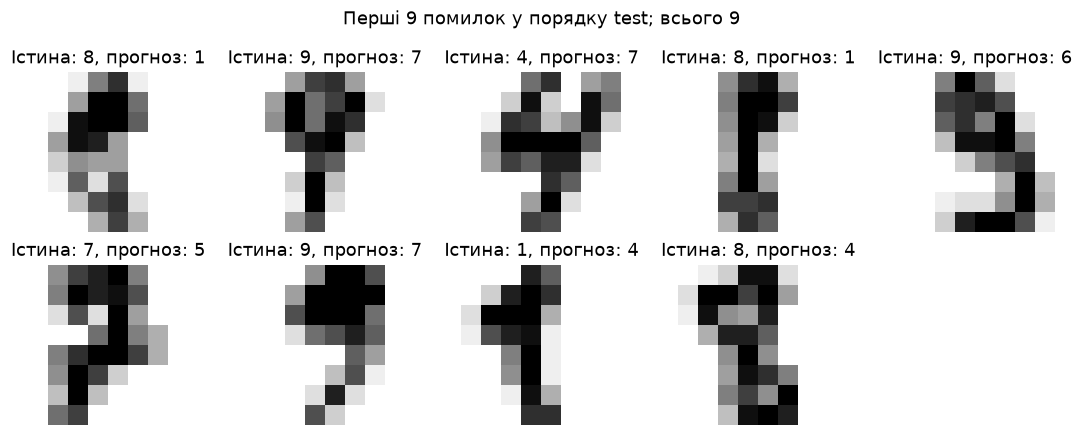

Найчастіша спрямована плутанина (перша при рівності): 8 → 1, випадків: 2.
Піксельні приклади дозволяють обговорити неоднозначність почерку, але причини помилок потребують окремої перевірки.


In [8]:
cm = confusion_matrix(y_test, pred, labels=range(10))
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set(xlabel='Передбачена цифра', ylabel='Справжня цифра', title=f'Матриця помилок: {selected_name}')
save_figure('confusion_matrix')
wrong = np.flatnonzero(pred != y_test)
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax in axes.flat:
    ax.axis('off')
for ax, i in zip(axes.flat, wrong[:10]):
    ax.imshow(X_test[i].reshape(8, 8), cmap='gray_r', vmin=0, vmax=16)
    ax.set_title(f'Істина: {y_test[i]}, прогноз: {pred[i]}')
fig.suptitle(f'Перші {min(10, len(wrong))} помилок у порядку test; всього {len(wrong)}')
save_figure('errors')
off_diagonal = cm.copy()
np.fill_diagonal(off_diagonal, 0)
if off_diagonal.max() > 0:
    a, b = np.unravel_index(off_diagonal.argmax(), cm.shape)
    print(f'Найчастіша спрямована плутанина (перша при рівності): {a} → {b}, випадків: {cm[a,b]}.')
print('Піксельні приклади дозволяють обговорити неоднозначність почерку, але причини помилок потребують окремої перевірки.')

## 7. Стійкість до шуму
До тих самих тестових зображень додаємо гаусівський шум зі стандартним
відхиленням 0, 1, 2, 4 у шкалі пікселів 0…16 та обрізаємо значення до [0,16].
Використовуємо один фіксований напрям шуму для порівняння його сили.
Модель не перенавчаємо. Результати залежні між собою й базуються на одній
реалізації шуму: це ілюстрація стійкості, а не оцінка для всіх спотворень.

,sigma,accuracy,macro_f1
0,0,0.9750,0.9748
1,1,0.1556,0.1211
2,2,0.1194,0.0563
3,4,0.1028,0.0239


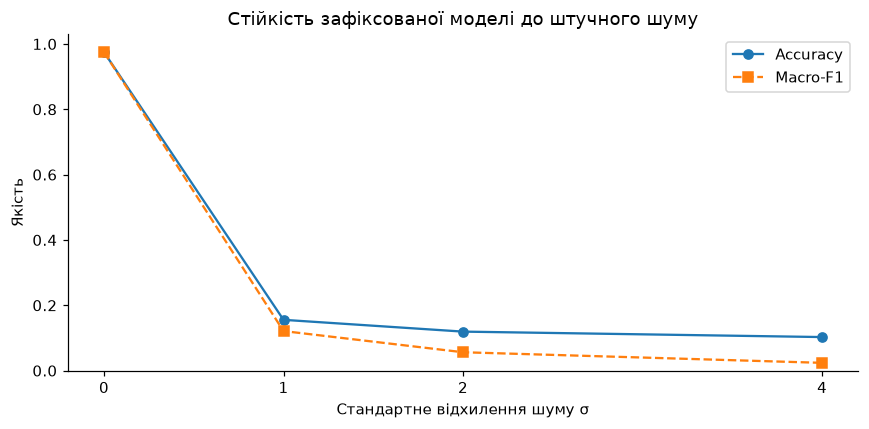

In [9]:
rng = np.random.default_rng(SEED)
unit_noise = rng.normal(size=X_test.shape)
noise_rows = []
for sigma in [0, 1, 2, 4]:
    noisy = np.clip(X_test + sigma * unit_noise, 0, 16)
    noisy_pred = best_model.predict(noisy)
    noise_rows.append({'sigma': sigma, 'accuracy': accuracy_score(y_test, noisy_pred), 'macro_f1': f1_score(y_test, noisy_pred, average='macro')})
noise_table = pd.DataFrame(noise_rows)
noise_table.to_csv(OUT / 'noise_robustness.csv', index=False)
display(noise_table.round(4))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(noise_table.sigma, noise_table.accuracy, 'o-', label='Accuracy')
ax.plot(noise_table.sigma, noise_table.macro_f1, 's--', label='Macro-F1')
ax.set(xlabel='Стандартне відхилення шуму σ', ylabel='Якість', title='Стійкість зафіксованої моделі до штучного шуму', ylim=(0, 1.03))
ax.set_xticks([0, 1, 2, 4])
ax.legend()
save_figure('noise_robustness')

## 8. Підсумки експерименту
Нижче висновок формується з фактично обчислених значень.

**Як інтерпретувати stress test:** шум додається також до фонових пікселів,
які в чистих даних майже завжди нульові. Це може суттєво змінити розподіл
ознак; StandardScaler може посилювати зміни ознак із малою дисперсією.
Тому цей дослід не доводить стійкості до шуму реального сканера й не є
тестом лише «невеликого візуального погіршення». Для встановлення причин
падіння потрібні окремі контрольні досліди зі способом нормалізації та фоном.

In [10]:
summary = {
    'seed': SEED, 'selection_rule': 'training_cv_macro_f1', 'selected_model': selected_name,
    'best_params': searches[selected_name].best_params_,
    'cv_macro_f1': {name: float(s.best_score_) for name, s in searches.items()},
    'test_accuracy': float(accuracy), 'test_macro_f1': float(macro_f1),
    'baseline_accuracy': float(baseline_accuracy), 'correct': correct, 'errors': int(len(wrong)),
    'accuracy_wilson_95': [float(ci.low), float(ci.high)],
    'train_indices': train_idx.tolist(), 'test_indices': test_idx.tolist(),
    'confusion_matrix': cm.tolist(), 'noise': noise_rows, 'versions': versions,
}
(OUT / 'metrics.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
conclusion = f'''## Фактичні результати

- За 5-fold CV обрано **{selected_name}**: macro-F1 **{searches[selected_name].best_score_:.4f}**.
- Параметри: `{searches[selected_name].best_params_}`.
- На незалежній тестовій частині: **accuracy {accuracy:.2%}**, **macro-F1 {macro_f1:.4f}**.
- Правильних відповідей **{correct}/360**, помилок **{len(wrong)}**.
- Baseline accuracy: **{baseline_accuracy:.2%}**; приріст **{100*(accuracy-baseline_accuracy):.2f} відсоткового пункту**.
- 95% Wilson-інтервал accuracy: **[{ci.low:.2%}; {ci.high:.2%}]**.
- При шумі σ=4 accuracy становить **{noise_rows[-1]['accuracy']:.2%}**.
- На learning curve validation macro-F1 зростає від **{curve.validation_f1.iloc[0]:.4f}** до **{curve.validation_f1.iloc[-1]:.4f}** при збільшенні навчальної частини fold із **{int(sizes[0])}** до **{int(sizes[-1])}** прикладів.

## Інтерпретація та обмеження

Модель виявляє закономірності зображень і перевершує прогноз найчастішого класу.
Оцінка стосується цього набору й фіксованого розбиття. Висока accuracy не означає
готовності до використання на фотографіях: інший фон, масштаб, поворот і освітлення
можуть погіршувати результат. Випадковий поділ не гарантує незалежності авторів
почерку; writer-independent оцінювання потребує відповідних ідентифікаторів.
Macro-F1 доповнює accuracy, але не враховує різної ціни помилок.
Кросвалідаційна оцінка після підбору параметрів може бути оптимістичною.
Шум різко знижує якість: модель чутлива до цього типу зміни розподілу.
Зростання validation macro-F1 на learning curve узгоджується з користю
додаткових даних у дослідженому діапазоні, але не гарантує подальшого зростання.

Подальша робота: дані від нових авторів, декілька розбиттів або nested CV,
аугментація на train та порівняння з нейронною мережею за тим самим протоколом.
Ці експерименти в цій роботі не виконувалися.
'''
display(Markdown(conclusion))
(OUT / 'conclusion.md').write_text(conclusion, encoding='utf-8')

## Фактичні результати

- За 5-fold CV обрано **SVC**: macro-F1 **0.9812**.
- Параметри: `{'model__C': 1, 'model__gamma': 'scale'}`.
- На незалежній тестовій частині: **accuracy 97.50%**, **macro-F1 0.9748**.
- Правильних відповідей **351/360**, помилок **9**.
- Baseline accuracy: **10.00%**; приріст **87.50 відсоткового пункту**.
- 95% Wilson-інтервал accuracy: **[95.32%; 98.68%]**.
- При шумі σ=4 accuracy становить **10.28%**.
- На learning curve validation macro-F1 зростає від **0.9227** до **0.9783** при збільшенні навчальної частини fold із **191** до **958** прикладів.

## Інтерпретація та обмеження

Модель виявляє закономірності зображень і перевершує прогноз найчастішого класу.
Оцінка стосується цього набору й фіксованого розбиття. Висока accuracy не означає
готовності до використання на фотографіях: інший фон, масштаб, поворот і освітлення
можуть погіршувати результат. Випадковий поділ не гарантує незалежності авторів
почерку; writer-independent оцінювання потребує відповідних ідентифікаторів.
Macro-F1 доповнює accuracy, але не враховує різної ціни помилок.
Кросвалідаційна оцінка після підбору параметрів може бути оптимістичною.
Шум різко знижує якість: модель чутлива до цього типу зміни розподілу.
Зростання validation macro-F1 на learning curve узгоджується з користю
додаткових даних у дослідженому діапазоні, але не гарантує подальшого зростання.

Подальша робота: дані від нових авторів, декілька розбиттів або nested CV,
аугментація на train та порівняння з нейронною мережею за тим самим протоколом.
Ці експерименти в цій роботі не виконувалися.


1581

## 9. Відповідність вимогам завдання
| Вимога | Реалізація |
|---|---|
| Обрати задачу | Багатокласова класифікація цифр |
| Обрати дані | Digits, 1797 зображень 8 × 8 |
| Навчання | fit, Pipeline, GridSearchCV на train |
| Оцінювання | CV, незалежний test, accuracy, macro-F1, classification report |
| ML-бібліотека | scikit-learn |
| Не писати алгоритми з нуля | Готові LogisticRegression, SVC, RandomForestClassifier |

## Джерела
- [Digits: дані та опис](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html)
- [UCI: першоджерело](https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits)
- [Pipeline та витік даних](https://scikit-learn.org/stable/common_pitfalls.html)
- [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)
- [Метрики класифікації](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics)